# Regularisation for Krylov Least Squares Algorithms in CIL

Reconstruction is posed as the minimisation of

$$\min_u \; \|Au - b\|_2^2 + \alpha\, \mathcal{R}(u),$$

a least-squares data fidelity plus a regulariser $\mathcal{R}$ weighted by
$\alpha$. CIL's Krylov solvers `LSQR` and `CGLS` handle the L2 priors
$\|Lu\|_2^2$ directly; the `IRLS` algorithm builds on them to reach the L1
priors $\|Lu\|_1$. This notebook demonstrates both on the simulated sphere:
first Tikhonov regularisation with `LSQR` and `CGLS`, then IRLS for L1
regularisation on wavelets and total variation, scored against `FISTA` on
the same objective.

In [1]:
from time import time

import matplotlib.pyplot as plt

from cil.optimisation.utilities.callbacks import Callback

from cil.optimisation.algorithms import CGLS, FISTA, IRLS, LSQR
from cil.optimisation.functions import (L1Norm, L1Sparsity, LeastSquares,
                                        TotalVariation)
from cil.optimisation.operators import GradientOperator, WaveletOperator
from cil.plugins.astra import ProjectionOperator
from cil.processors import Slicer, TransmissionAbsorptionConverter
from cil.recon import FDK
from cil.utilities import dataexample
from cil.utilities.display import show2D

DATA = '2d'
ANGLE_STEP = 5
OUTER = 10
INNER = 50
FISTA_ITERATIONS = OUTER * INNER

L2_ITERATIONS = 200
ALPHA_TIKHONOV = 100
ALPHA_TIKHONOV_GRADIENT = 200
ALPHA_HAAR = 0.8
ALPHA_TV = 2.5


In [2]:
def relative_rmse(u, ground_truth):
    return float((u - ground_truth).norm() / ground_truth.norm())


def centre_slice(x):
    """The container itself in 2D, its centre slice in 3D."""
    array = x.as_array()
    return array if array.ndim == 2 else array[array.shape[0] // 2]

class RMSETrace(Callback):
    """Relative RMSE against the ground truth after each outer iteration."""

    def __init__(self):
        self.rmse = []

    def __call__(self, algorithm):
        self.rmse.append(relative_rmse(algorithm.get_output(), ground_truth))


def plot_rmse_traces(traces, title, xlabel='outer iteration', steps=None):
    fig, ax = plt.subplots(figsize=(6, 4))
    for label, rmse in traces.items():
        step = steps[label] if steps else 1
        ax.semilogy([i * step for i in range(len(rmse))], rmse, label=label)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('relative RMSE vs ground truth')
    ax.set_title(title)
    ax.legend()
    plt.show()


## Load data

A simulated sphere phantom from `cil.utilities.dataexample`, converted to
absorption and subsampled in angle. FDK gives the unregularised reference;
it is *not* where anything starts.

FDK recon

Input Data:
	angle: 60
	horizontal: 128

Reconstruction Volume:
	horizontal_y: 128
	horizontal_x: 128

Reconstruction Options:
	Backend: tigre
	Filter: ram-lak
	Filter cut-off frequency: 1.0
	FFT order: 8
	Filter_inplace: False



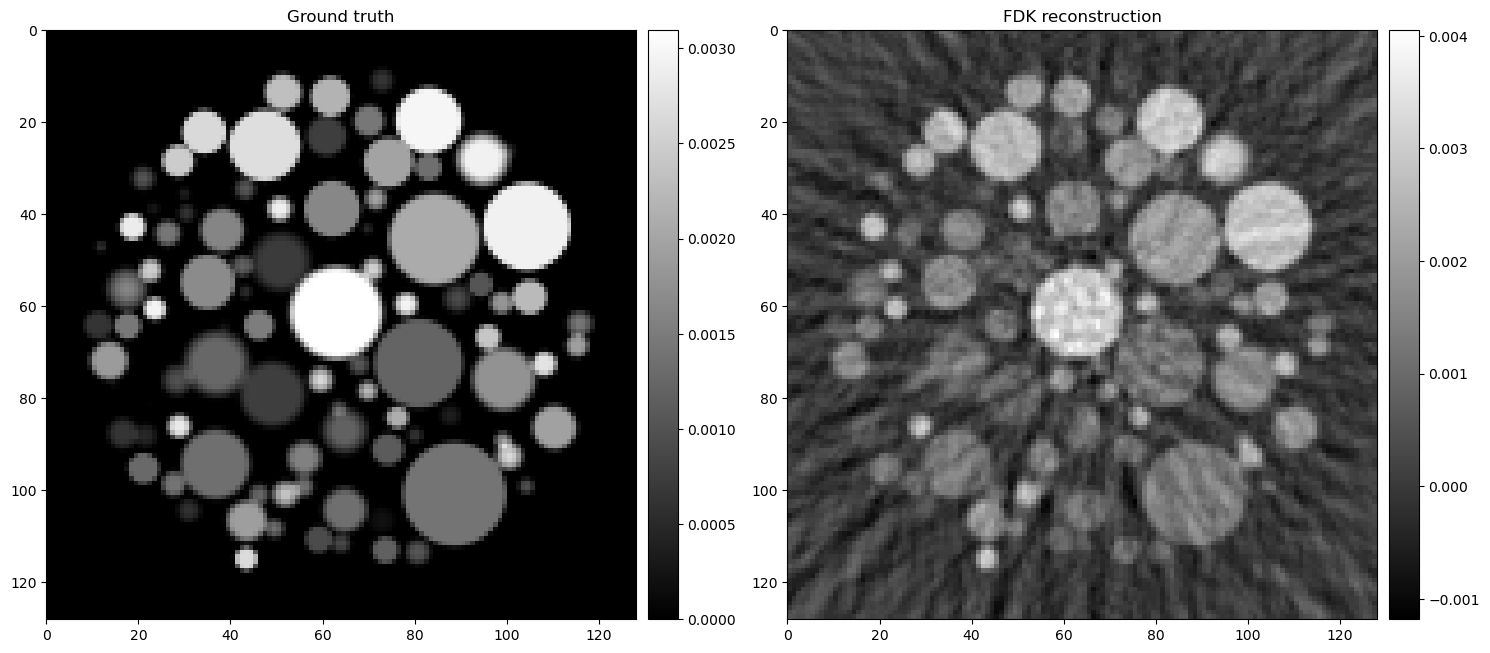

In [3]:
ground_truth = dataexample.SIMULATED_SPHERE_VOLUME.get()
data = dataexample.SIMULATED_CONE_BEAM_DATA.get()
if DATA == '2d':
    data = data.get_slice(vertical='centre')
    ground_truth = ground_truth.get_slice(vertical='centre')

data = TransmissionAbsorptionConverter()(data)
data = Slicer(roi={'angle': (0, -1, ANGLE_STEP)})(data)

# FDK runs on the TIGRE ordering, the solvers on Astra's
data.reorder('tigre')
fdk_recon = FDK(data, image_geometry=ground_truth.geometry).run()
data.reorder('astra')
ground_truth.reorder('astra')
fdk_recon.reorder('astra')

ig = ground_truth.geometry
A = ProjectionOperator(image_geometry=ig, acquisition_geometry=data.geometry)

initial = A.domain_geometry().allocate(0)

show2D([centre_slice(ground_truth), centre_slice(fdk_recon)],
       title=['Ground truth', 'FDK reconstruction'],
       origin='upper', num_cols=2)


## 1. Tikhonov regularisation with LSQR and CGLS

With the least-squares fidelity and the L2 prior, the problem is

$$\operatorname*{arg\,min}_u \; \|Au - b\|_2^2 + \alpha^2 \|Lu\|_2^2 ,$$

where the `alpha` argument of the solvers is $\alpha$ and `struct_operator`
is $L$ (`None` means the identity). With the identity the penalty damps the
solution, stabilising the semi-convergence of a long Krylov solve; the two
solvers minimise the same objective and should land in the same place.

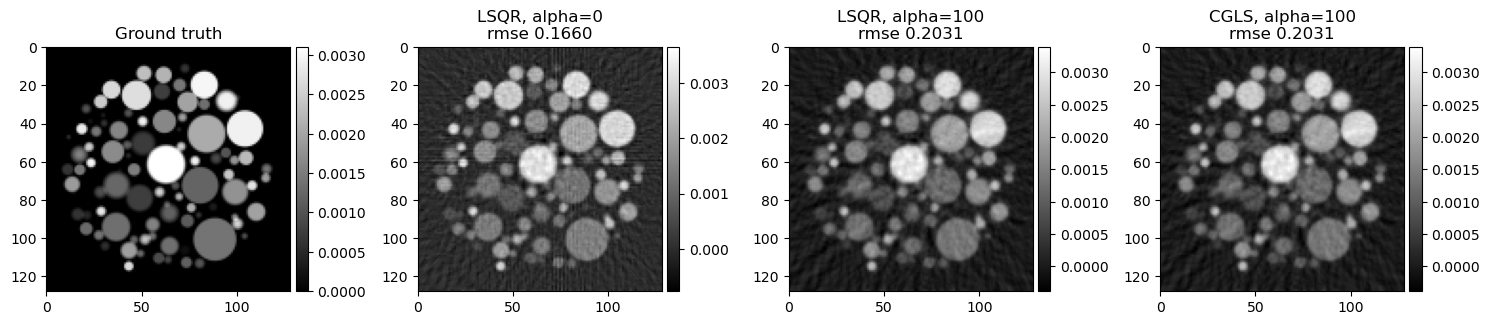

In [4]:
runs = [
    ('LSQR, alpha=0', LSQR(initial=initial, operator=A, data=data)),
    (f'LSQR, alpha={ALPHA_TIKHONOV}', LSQR(initial=initial, operator=A, data=data,
                  alpha=ALPHA_TIKHONOV)),
    (f'CGLS, alpha={ALPHA_TIKHONOV}', CGLS(initial=initial, operator=A, data=data,
                  alpha=ALPHA_TIKHONOV)),
]

titles = ['Ground truth']
for label, algorithm in runs:
    algorithm.run(L2_ITERATIONS, verbose=0)
    titles.append('{}\nrmse {:.4f}'.format(
        label, relative_rmse(algorithm.get_output(), ground_truth)))

show2D([centre_slice(ground_truth)]
       + [centre_slice(algorithm.solution) for _, algorithm in runs],
       title=titles, origin='upper', num_cols=4)


### 1.1 The regularising operator $L$

$L$ is the only thing that has to change to change the regulariser: the
identity damps towards zero, a `GradientOperator` rewards smoothness, a
`WaveletOperator` shrinks the wavelet coefficients. 

Whether $L$ is*orthogonal* (and square) decides which `form` the solvers can use:

**Block form** (the default) iterates on the stacked problem

$$\operatorname*{arg\,min}_u \;
\left\| \begin{pmatrix} A \\ \alpha L \end{pmatrix} u
- \begin{pmatrix} b \\ 0 \end{pmatrix} \right\|_2^2 ,$$

which accepts any $L$ and always warm starts, at the price of containers
over both $\mathrm{Range}(A)$ and $\mathrm{Range}(L)$.

**Standard form** changes variables to $v = Lu$ and iterates on

$$\|AL^{-1}v - b\|_2^2 + \alpha^2\|v\|_2^2,$$

with $\alpha$ handled inside the
solvers' own recurrences -- no stacked containers. It needs an orthogonal,
square $L$ (so $L^{-1} = L^*$) and in it only CGLS can warm start: LSQR's
penalty lands on the step rather than the solution.

In [5]:
haar = WaveletOperator(ig, wname='haar')
db4 = WaveletOperator(ig, wname='db4', bnd_cond='periodization')
gradient = GradientOperator(ig)

for name, L in [('identity', None), ('Haar', haar), ('Db4', db4),
                ('gradient', gradient)]:
    print('{:<10} orthogonal: {}'.format(
        name, True if L is None else L.is_orthogonal()))


identity   orthogonal: True
Haar       orthogonal: True
Db4        orthogonal: True
gradient   orthogonal: False


### 1.2 Tikhonov with a gradient $L$

`struct_operator=GradientOperator(ig)` penalises $\alpha^2\|\nabla u\|_2^2$,
a smoothness prior. The gradient is not invertible, so only the (default)
block form is available; everything else is the same call.

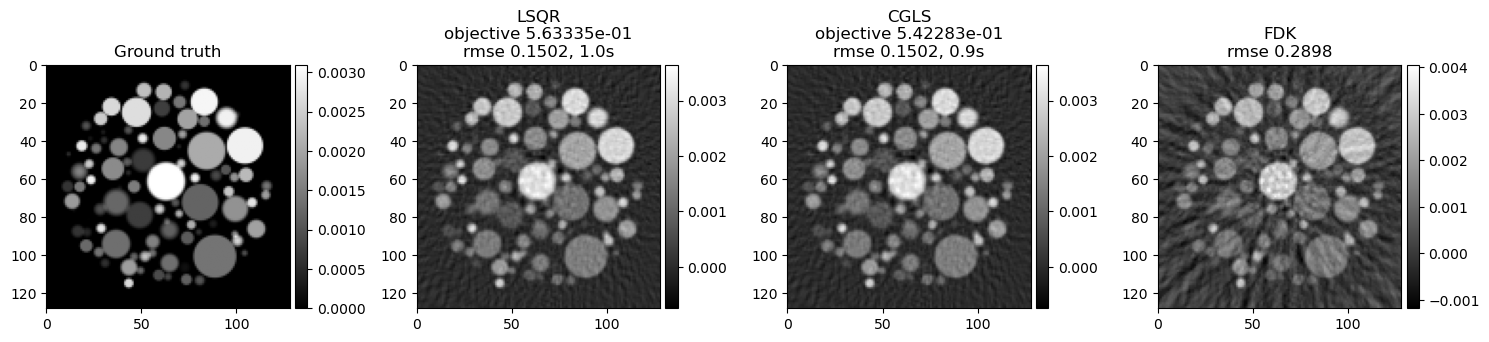

In [6]:
runs = [
    ('LSQR', LSQR(initial=initial, operator=A, data=data,
                  alpha=ALPHA_TIKHONOV_GRADIENT, struct_operator=gradient)),
    ('CGLS', CGLS(initial=initial, operator=A, data=data,
                  alpha=ALPHA_TIKHONOV_GRADIENT, struct_operator=gradient)),
]

titles = ['Ground truth']
for label, algorithm in runs:
    t0 = time()
    algorithm.run(L2_ITERATIONS, verbose=0)
    titles.append('{}\nobjective {:.5e}\nrmse {:.4f}, {:.1f}s'.format(
        label, algorithm.objective[-1],
        relative_rmse(algorithm.get_output(), ground_truth), time() - t0))
titles.append('FDK\nrmse {:.4f}'.format(
    relative_rmse(fdk_recon, ground_truth)))

# reused in section 2.2
tikhonov_gradient_solution = runs[0][1].get_output().copy()

show2D([centre_slice(ground_truth), centre_slice(runs[0][1].solution),
        centre_slice(runs[1][1].solution), centre_slice(fdk_recon)],
       title=titles, origin='upper', num_cols=4)


## 2. L1 regularisation with IRLS

`IRLS` solves

$$\min_u \; \|Au - b\|_2^2 + \alpha^2 \|Lu\|_1$$

by repeatedly solving the weighted Tikhonov problem of section 1,

$$\min_u \; \|Au - b\|_2^2 + \alpha^2 \|W_k L u\|_2^2,
\qquad
w_k = \bigl(|Lu_{k-1}|^2 + \tau_k^2\bigr)^{-1/4},$$

with an inner `LSQR` or `CGLS`; the weights are rebuilt from the iterate
between inner solves and the smoothing $\tau_k$ shrinks as the loop
proceeds. With the gradient as $L$ this is *anisotropic* TV -- the partial
derivatives are reweighted independently -- so the FISTA comparison below
uses `TotalVariation(isotropic=False)` to match.

### 2.1 Setting up IRLS

IRLS is an outer loop around an inner Krylov solver, built in one step: it
owns the problem, builds the inner solver itself and manages the weights.
The arguments are those of `LSQR`/`CGLS` plus the loop controls:
`inner_solver` (the class, `LSQR` by default), `max_inner_iteration` (inner
iterations per reweighting) and the `tau` schedule.

In [7]:
irls = IRLS(initial=initial, operator=A, data=data, alpha=ALPHA_HAAR,
            struct_operator=haar, inner_solver=LSQR,
            max_inner_iteration=INNER)

irls.run(OUTER, verbose=1)
haar_solution = irls.get_output().copy()


`irls.objective` is the true objective
$\|Au-b\|_2^2 + \alpha^2\|Lu\|_1$ at the current solution, recorded each
outer iteration, so it is directly comparable with FISTA's. The reweighted
least-squares residual the inner solver works against is a different
quantity, available as `irls.inner_solver.loss`.

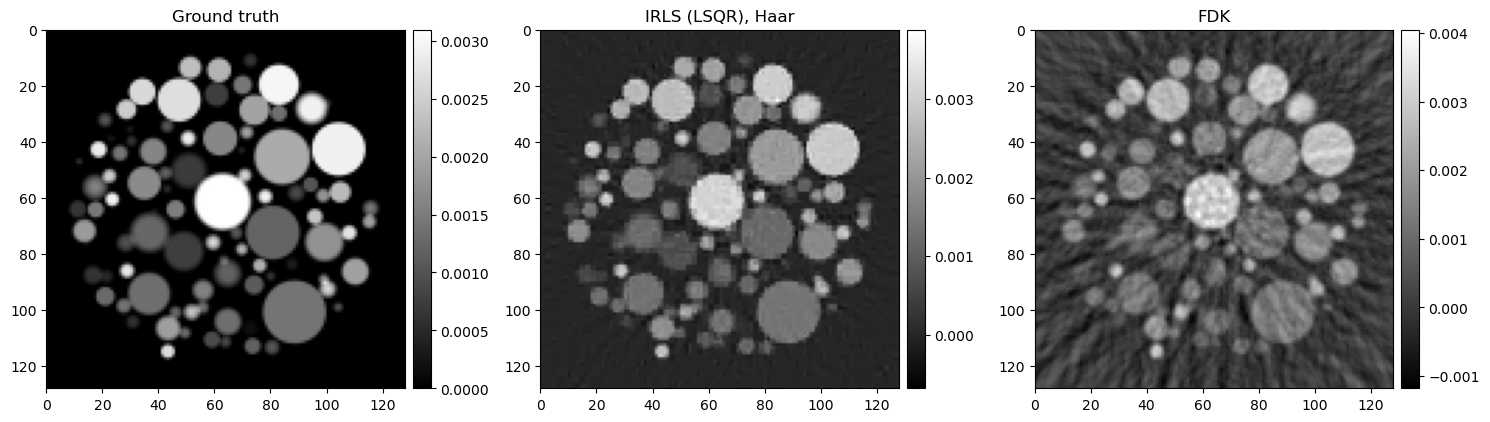

In [8]:
show2D([centre_slice(ground_truth), centre_slice(haar_solution),
        centre_slice(fdk_recon)],
       title=['Ground truth', 'IRLS (LSQR), Haar', 'FDK'],
       origin='upper', num_cols=3)


### 2.2 Total variation

The same `GradientOperator` that gave the smoothness prior in section 1.2
gives (anisotropic) total variation under the L1 penalty: the L2 penalty
smooths the edges it wants to keep, the L1 penalty keeps them.

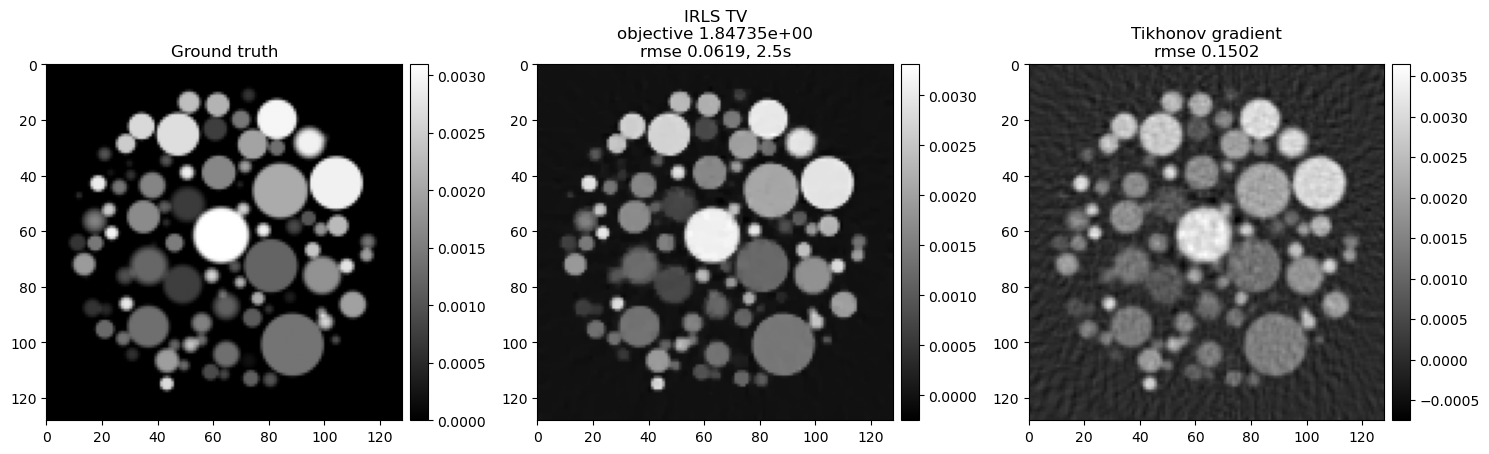

In [9]:
irls_tv = IRLS(initial=initial, operator=A, data=data, alpha=ALPHA_TV,
               struct_operator=gradient, max_inner_iteration=INNER)
t0 = time()
irls_tv.run(OUTER, verbose=1)
tv_time = time() - t0
tv_solution = irls_tv.get_output().copy()

show2D([centre_slice(ground_truth), centre_slice(tv_solution),
        centre_slice(tikhonov_gradient_solution)],
       title=['Ground truth',
              'IRLS TV\nobjective {:.5e}\nrmse {:.4f}, {:.1f}s'.format(
                  irls_tv.objective[-1],
                  relative_rmse(tv_solution, ground_truth), tv_time),
              'Tikhonov gradient\nrmse {:.4f}'.format(
                  relative_rmse(tikhonov_gradient_solution, ground_truth))],
       origin='upper', num_cols=3)


### 2.3 Why warm starting helps

Each outer iteration solves a fresh Tikhonov problem that differs from the
previous one only through the weights. With `warm_start=True` (the default)
every inner solve begins at the previous outer iterate; with
`warm_start=False` it restarts from `initial` and has to rebuild the
reconstruction within its own inner budget. The runs below start from the
FDK reconstruction, where the effect is starkest: the warm run overtakes a
cold run given five times the budget.

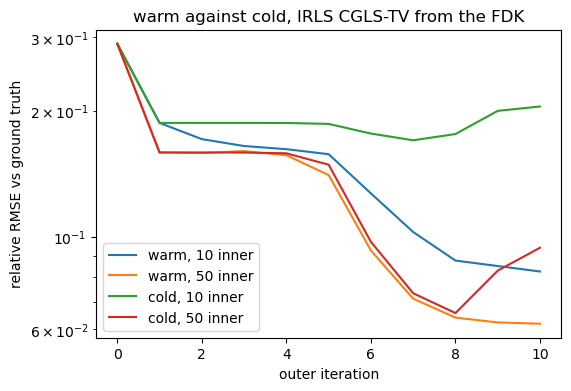

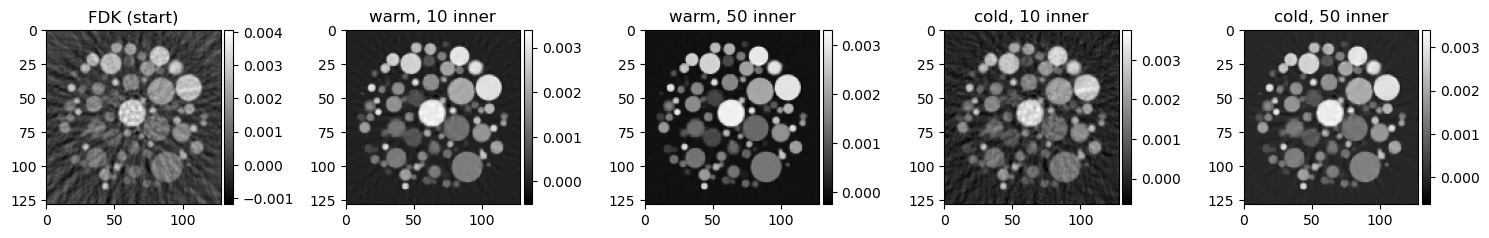

In [10]:
runs = [('warm, 10 inner', True, 10),
        ('warm, 50 inner', True, 50),
        ('cold, 10 inner', False, 10),
        ('cold, 50 inner', False, 50)]

traces, finals = {}, []
for label, warm, inner in runs:
    irls = IRLS(initial=fdk_recon, operator=A, data=data, alpha=ALPHA_TV,
                struct_operator=gradient, inner_solver=CGLS,
                max_inner_iteration=inner, warm_start=warm)
    trace = RMSETrace()
    irls.run(OUTER, callbacks=[trace], verbose=0)
    traces[label] = trace.rmse
    finals.append((label, irls.get_output().copy()))

plot_rmse_traces(traces, 'warm against cold, IRLS CGLS-TV from the FDK')

show2D([centre_slice(fdk_recon)] + [centre_slice(s) for _, s in finals],
       title=['FDK (start)'] + [label for label, _ in finals],
       origin='upper', num_cols=5)


### 2.4 Cooling the smoothing parameter, $\tau$

$\tau$ keeps the weights finite where $Lu = 0$ and sets how closely the
reweighted quadratic approximates the L1 penalty. IRLS cools it from
`tau=1.0` by `tau_factor=0.1` per outer iteration, so the early subproblems
are well-conditioned and the hard, nearly-L1 ones only arrive once the
iterate is good. Keeping $\tau$ tiny from the start makes every subproblem
as ill-conditioned as the last -- hardest on CGLS, which works with the
square of the condition number -- and never cooling stalls at the smoothed
objective.

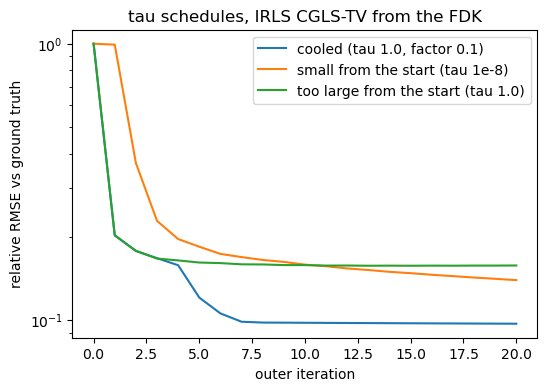

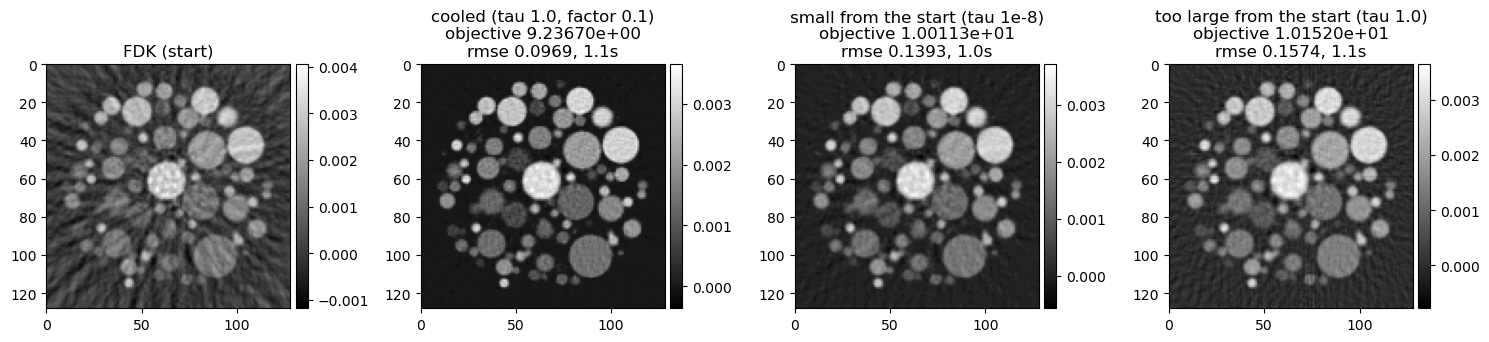

In [18]:
tau_runs = [('cooled (tau 1.0, factor 0.1)', 1.0, 0.1),
            ('small from the start (tau 1e-8)', 1e-8, 1.0),
            ('too large from the start (tau 1.0)', 1.0, 1.0)]

tau_traces, tau_panels, tau_titles = {}, [], []
for label, tau, tau_factor in tau_runs:
    irls = IRLS(initial=initial, operator=A, data=data, alpha=1.0,
                max_inner_iteration=10, tau=tau, tau_factor=tau_factor)

    trace = RMSETrace()
    t0 = time()
    irls.run(20, callbacks=[trace], verbose=0)
    tau_traces[label] = trace.rmse
    tau_panels.append(irls.get_output().copy())
    tau_titles.append('{}\nobjective {:.5e}\nrmse {:.4f}, {:.1f}s'.format(
        label, irls.objective[-1], trace.rmse[-1], time() - t0))

plot_rmse_traces(tau_traces, 'tau schedules, IRLS CGLS-TV from the FDK')

show2D([centre_slice(fdk_recon)] + [centre_slice(p) for p in tau_panels],
       title=['FDK (start)'] + tau_titles,
       origin='upper', num_cols=4)


### 2.5 The FISTA reference

FISTA minimises $f(u) + g(u)$ with $f = \texttt{LeastSquares(A, data)}
= \|Au-b\|_2^2$ (no factor of a half) and $g = \alpha^2\|Lu\|_1$, so $g$
carries $\alpha$ *squared* to match IRLS. The prox must be the same penalty:
`L1Norm()` for the identity, `L1Sparsity(L)` for an orthogonal wavelet and
`TotalVariation(isotropic=False)` for the gradient -- only the last is
approximate, an inner FGP loop rather than a closed form.

In [12]:
REGULARISERS = [
    ('L1', None, 1.0, L1Norm()),
    ('L1 Wavelet (Db4)', db4, 1.0, L1Sparsity(db4)),
    ('TV', gradient, ALPHA_TV, TotalVariation(isotropic=False)),
]


### 2.6 Regularisation for LSQR, CGLS and FISTA comparisons

Three regularisers -- plain L1, the Db4 wavelet and TV -- each solved by
IRLS with either inner solver and by FISTA on the same objective.


--- L1 (alpha = 1.0) ---


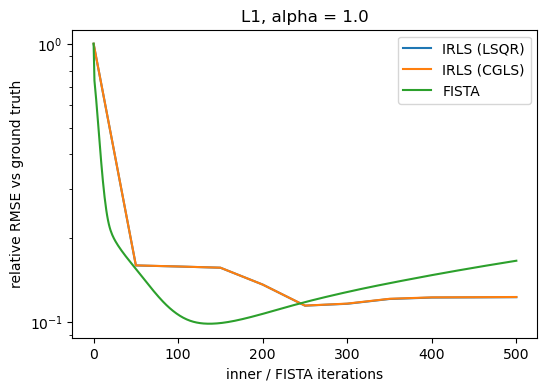

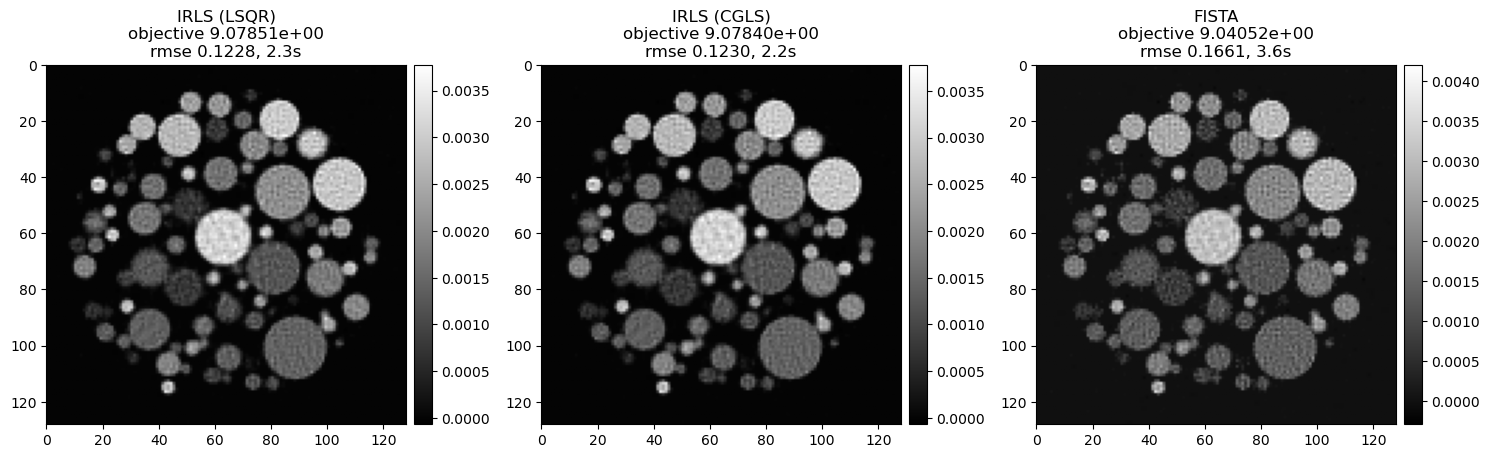


--- L1 Wavelet (Db4) (alpha = 1.0) ---


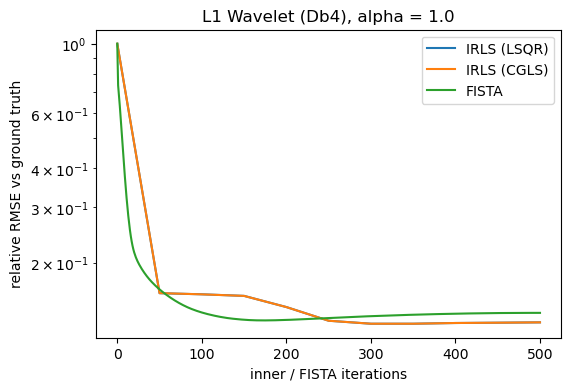

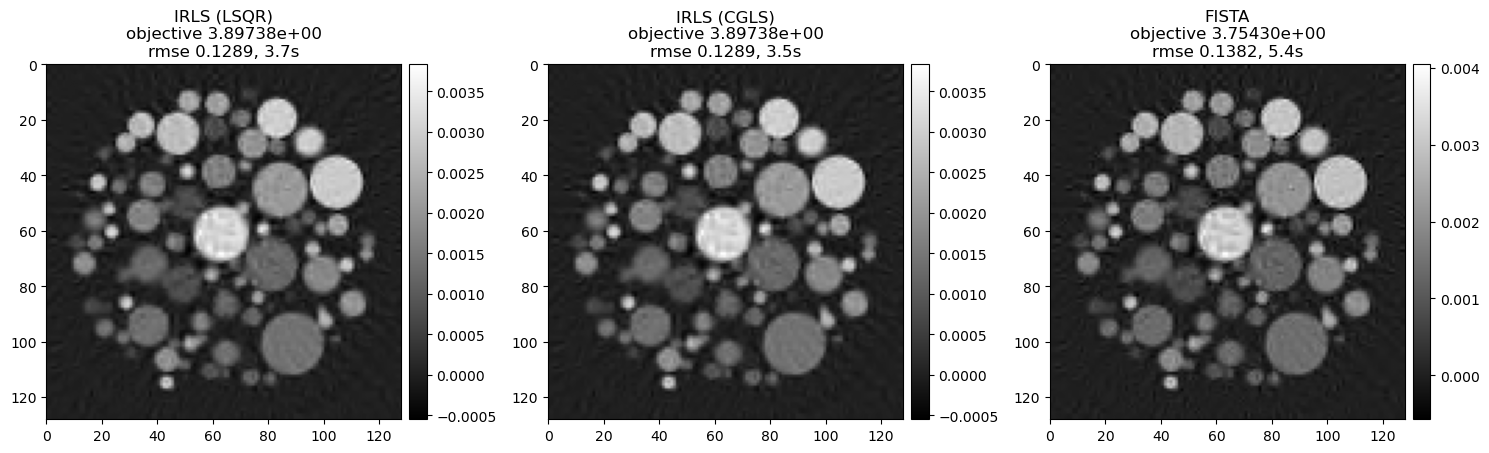


--- TV (alpha = 2.5) ---


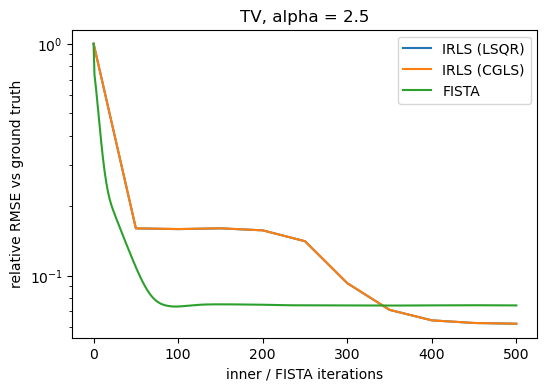

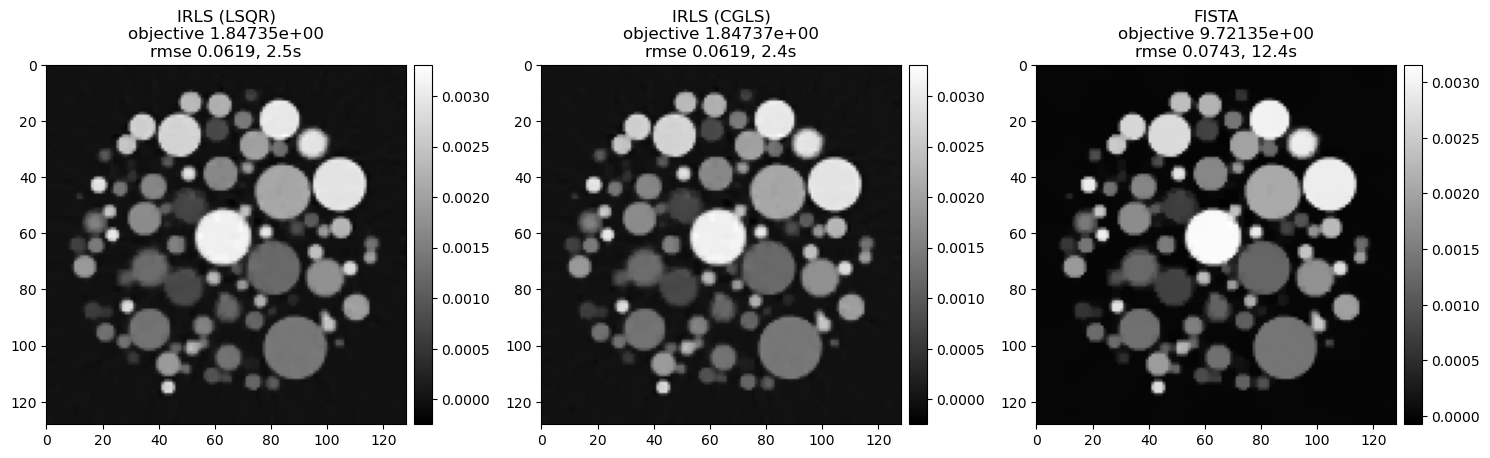

In [19]:
for name, L, alpha, g in REGULARISERS:
    print('\n--- {} (alpha = {}) ---'.format(name, alpha))
    runs = [('IRLS ({})'.format(solver.__name__),
             IRLS(initial=initial, operator=A, data=data, alpha=alpha,
                  struct_operator=L, inner_solver=solver,
                  max_inner_iteration=INNER), OUTER)
            for solver in (LSQR, CGLS)]
    runs.append(('FISTA', FISTA(initial=initial, f=LeastSquares(A, data),
                                g=alpha ** 2 * g), FISTA_ITERATIONS))

    panels, titles, traces, steps = [], [], {}, {}
    for label, algorithm, iterations in runs:
        trace = RMSETrace()
        t0 = time()
        algorithm.run(iterations, callbacks=[trace], verbose=0)
        traces[label] = trace.rmse
        steps[label] = INNER if isinstance(algorithm, IRLS) else 1
        panels.append(algorithm.get_output().copy())
        titles.append('{}\nobjective {:.5e}\nrmse {:.4f}, {:.1f}s'.format(
            label, algorithm.objective[-1],
            relative_rmse(panels[-1], ground_truth), time() - t0))

    # one IRLS outer iteration costs INNER inner iterations: a shared work axis
    plot_rmse_traces(traces, '{}, alpha = {}'.format(name, alpha),
                     xlabel='inner / FISTA iterations', steps=steps)

    show2D([centre_slice(p) for p in panels], title=titles,
           origin='upper', num_cols=3)


### 2.7 Standard form verus block form for orthogonal L

CGLS warm starts in either form, so for an orthogonal, square $L$ the two
forms should reach the same place. Of the regularisers above, that admits
plain L1 and the Db4 wavelet; TV has no standard form.


--- L1 (alpha = 1.0) ---
the two forms differ by 4.998e-02, relative


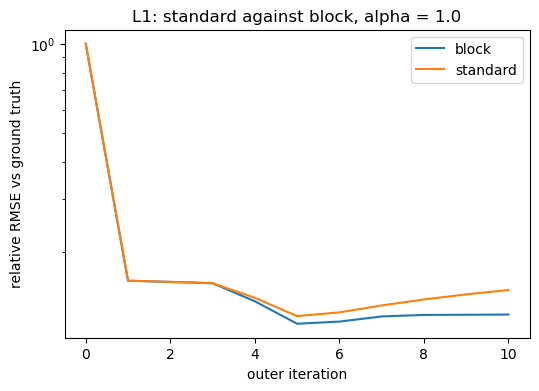

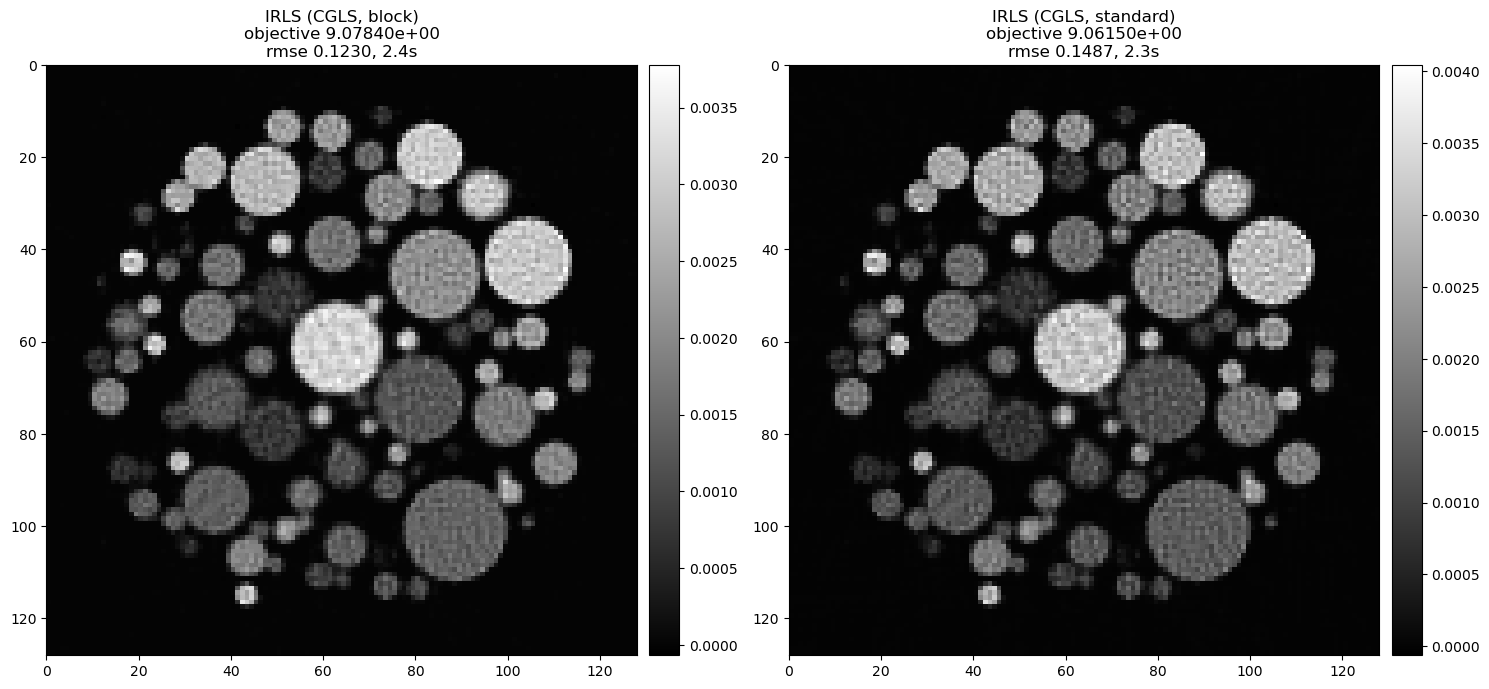


--- L1 Wavelet (Db4) (alpha = 1.0) ---
the two forms differ by 2.137e-02, relative


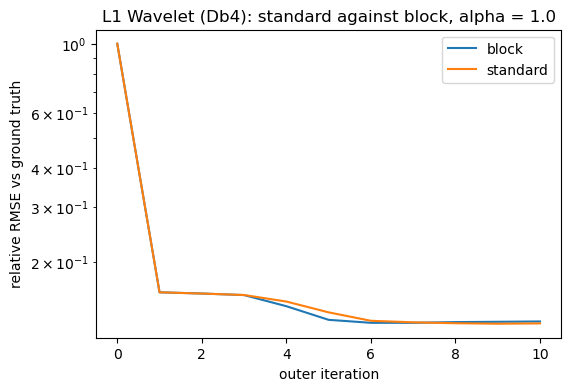

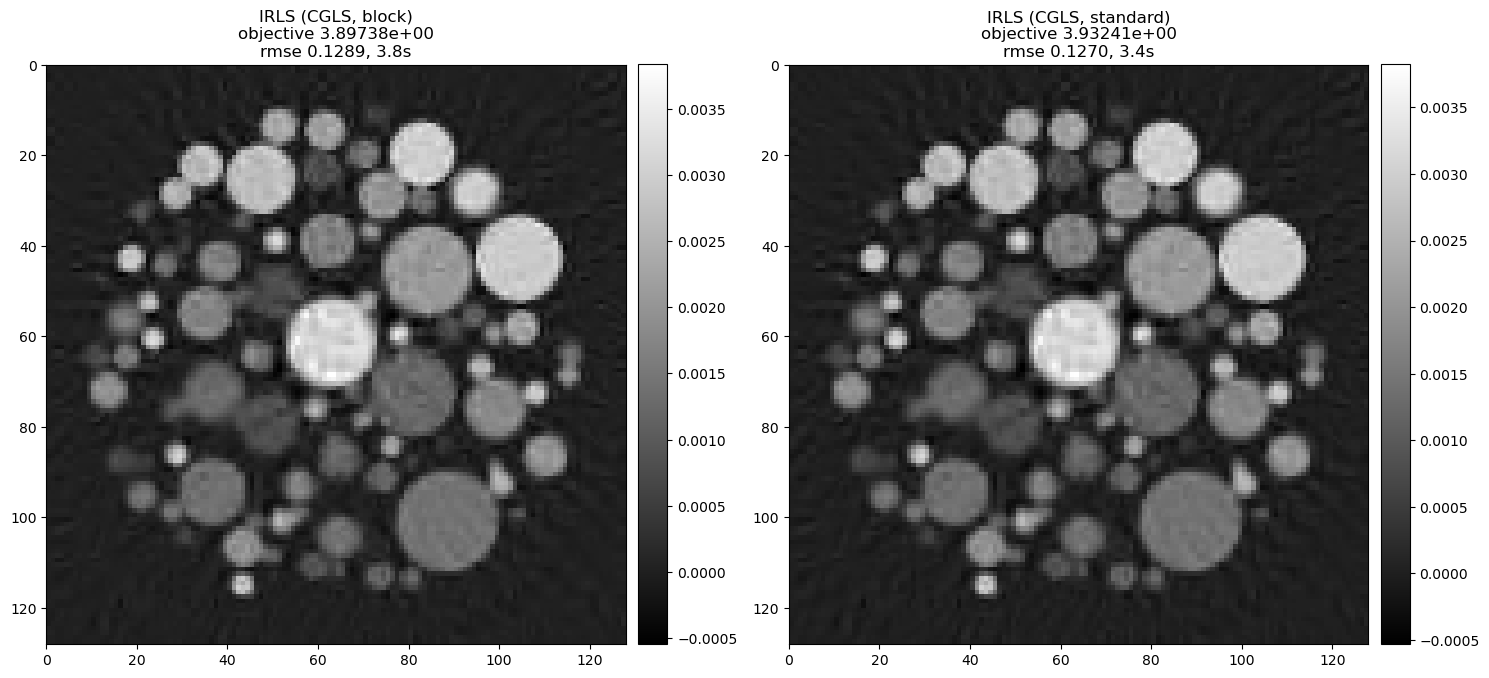

In [14]:
for name, L, alpha, _ in REGULARISERS:
    if L is not None and not L.is_orthogonal():
        continue
    print('\n--- {} (alpha = {}) ---'.format(name, alpha))

    solutions, titles, traces = {}, [], {}
    for form in ('block', 'standard'):
        algorithm = IRLS(initial=initial, operator=A, data=data,
                         alpha=alpha, struct_operator=L, inner_solver=CGLS,
                         form=form, max_inner_iteration=INNER)
        trace = RMSETrace()
        t0 = time()
        algorithm.run(OUTER, callbacks=[trace], verbose=0)
        traces[form] = trace.rmse
        solutions[form] = algorithm.get_output().copy()
        titles.append(
            'IRLS (CGLS, {})\nobjective {:.5e}\nrmse {:.4f}, {:.1f}s'.format(
                form, algorithm.objective[-1],
                relative_rmse(solutions[form], ground_truth), time() - t0))

    difference = ((solutions['block'] - solutions['standard']).norm()
                  / solutions['block'].norm())
    print('the two forms differ by {:.3e}, relative'.format(difference))

    plot_rmse_traces(traces, '{}: standard against block, alpha = {}'.format(name, alpha))

    show2D([centre_slice(solutions['block']),
            centre_slice(solutions['standard'])],
           title=titles, origin='upper', num_cols=2)


## What to try next

* **`DATA = '3d'`** in the first cell runs the identical code on the full
  volume. Nothing else changes; the figures show the central slice.
* **`alpha`** is the parameter to move first. Too large over-smooths badly --
  on real data TV at $\alpha = 2.5$ is visibly worse than at
  $\alpha = 0.05$.